# Data Understanding: EDA

Interim report, component 2 (Data understanding): data sources, size, characteristics, examples, exploration findings, and how the synthetic (translated) data was produced.

**Sources**
- `data/original/PL_train.csv`: Polish parliamentary debate fragments annotated with 25 persuasion techniques, from [SlavicNLP/SlavicPersuasionTechniques](https://github.com/SlavicNLP/SlavicPersuasionTechniques) (`data/PL/train.csv`), described in Piskorski et al., LREC 2026.
- `data/translated/PL_{train,test}_translated_lapa.csv`: the same rows machine-translated to Ukrainian (`content_uk`) by the **Lapa LLM** (`lapa-llm/lapa-v0.1.3-instruct`). This is our synthetic Ukrainian data. Lapa was chosen after comparing it with DeepL and Opus-MT on 100 rows (see `translation_evaluation/`).

Runs on Colab (clones the repo) or locally (finds the repo root). CPU is enough.

In [1]:
import ast, re, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPO_URL = "https://github.com/vivtrea/2026_NLP_Course_Project_Detecting_Persuasion_UKRParlTexts.git"

if "google.colab" in sys.modules:
    if not Path("repo").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "repo"], check=True)  # private repo: use a URL with a token
    ROOT = Path("repo")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())

DATA = ROOT / "data"
pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.dpi"] = 110
print("Data dir:", DATA.resolve())

Data dir: /content/repo/data


## 1. Load

In [2]:
GROUPS = ["Attack_on_Reputation", "Justification", "Distraction", "Simplification", "Call", "Manipulative_Wording"]

def load(path, split):
    df = pd.read_csv(path)
    df["split"] = split
    df["techniques"] = df["techniques"].apply(ast.literal_eval)
    df["n_techniques"] = df["techniques"].str.len()
    df["persuasive"] = df["n_techniques"] > 0
    # filenames look like pl_<topic>_<dd>_<mm>_<yyyy>_n<k>.txt
    df["topic"] = df["filename"].str.replace(r"^pl_|_\d{2}_\d{2}_\d{4}_n\d+\.txt$", "", regex=True)
    df["words_pl"] = df["content"].str.split().str.len()
    df["words_uk"] = df["content_uk"].fillna("").str.split().str.len()
    return df

train = load(DATA / "translated" / "PL_train_translated_lapa.csv", "train")
test = load(DATA / "translated" / "PL_test_translated_lapa.csv", "test")
df = pd.concat([train, test], ignore_index=True)

# the translated train file must be the original Polish file plus one column
orig = pd.read_csv(DATA / "original" / "PL_train.csv")
assert len(orig) == len(train) and (orig["content"].values == train["content"].values).all()

train.head(3)

,filename,start,end,content,techniques,persuasion_strategies,Attack_on_Reputation,Justification,Distraction,Simplification,Call,Manipulative_Wording,content_uk,split,n_techniques,persuasive,topic,words_pl,words_uk
0,pl_hate_speech_act_19_12_2024_n08.txt,8047,8101,Ciągle pokutuje mit o Polsce jako kraju tolerancyjnym.,"[Appeal_to_Hypocrisy, Doubt]",['Attack_on_Reputation'],True,False,False,False,False,False,Постійно існує міф про Польщу як про толерантну країну.,train,2,True,hate_speech_act,8,9
1,pl_defence_22_05_2024_n01.txt,3160,3187,Rzeczywiście to jest hańba.,"[Exaggeration-Minimisation, Loaded_Language]",['Manipulative_Wording'],False,False,False,False,False,True,"Дійсно, це ганьба.",train,2,True,defence,4,3
2,pl_current_affairs_09_01_2025_n02.txt,3965,4288,Posłowie Joanna Borowiak i Anna Gembicka z Klubu Parlamentarnego Prawo i Sprawiedliwość zadadzą pytania w sprawie decyzji generalnego dyrektora ochrony środowiska z grudnia 2024 r. torpedującej bu...,[Loaded_Language],['Manipulative_Wording'],False,False,False,False,False,True,Народні депутати Йоанна Боров'як та Анна Гембіцька з парламентського клубу «Право і Справедливість» зададуть питання щодо рішення генерального директора з охорони навколишнього середовища від груд...,train,1,True,current_affairs,41,42


## 2. Size and quality

In [3]:
overview = df.groupby("split").agg(
    fragments=("content", "size"),
    documents=("filename", "nunique"),
    persuasive_share=("persuasive", "mean"),
    mean_techniques=("n_techniques", "mean"),
    median_words_pl=("words_pl", "median"),
).round(3)
display(overview)

print("Missing values:", df[["content", "content_uk", "techniques"]].isna().sum().to_dict())
print("Duplicate fragments within train:", train["content"].duplicated().sum())
print("Fragments shared by train and test:", len(set(train["content"]) & set(test["content"])))
print("Documents shared by train and test:", len(set(train["filename"]) & set(test["filename"])), "of", df["filename"].nunique())

,fragments,documents,persuasive_share,mean_techniques,median_words_pl
split,,,,,
test,460,53,0.483,0.796,12.0
train,2809,53,0.533,0.837,13.0


Missing values: {'content': 0, 'content_uk': 0, 'techniques': 0}
Duplicate fragments within train: 0
Fragments shared by train and test: 0
Documents shared by train and test: 53 of 53


The train/test split is made **per fragment, not per document**: every source document appears in both splits. No text is duplicated, but the model sees other fragments of the same speeches (speaker, topic, style) at training time, so test scores may be optimistic. A document-level split would be stricter.

## 3. Topics

split,test,train,persuasive_share
topic,,,
abortion,140,798,0.63
defence,109,718,0.58
eu,98,563,0.39
hate_speech_act,58,379,0.61
statements,36,196,0.26
current_affairs,19,155,0.32


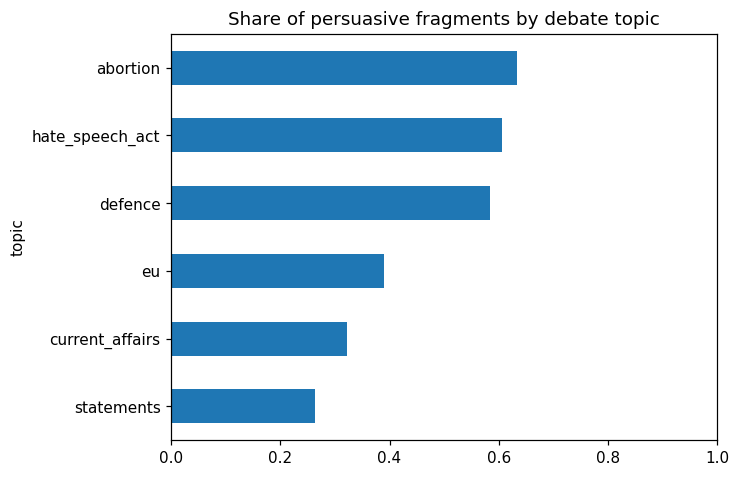

In [4]:
topics = df.groupby(["topic", "split"]).size().unstack()
topics["persuasive_share"] = df.groupby("topic")["persuasive"].mean().round(2)
display(topics.sort_values("train", ascending=False))

df.groupby("topic")["persuasive"].mean().sort_values().plot.barh(title="Share of persuasive fragments by debate topic", xlim=(0, 1))
plt.show()

## 4. Labels

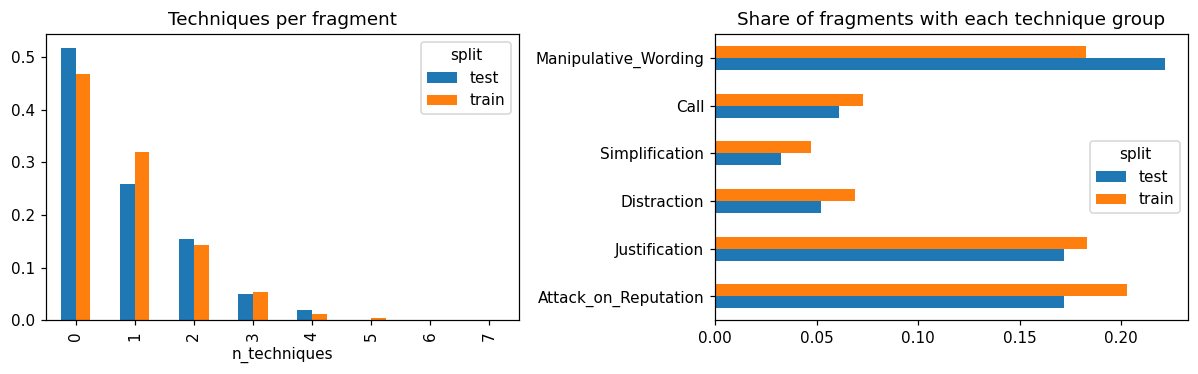

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df.groupby("split")["n_techniques"].value_counts(normalize=True).unstack(0).plot.bar(ax=axes[0], title="Techniques per fragment")
df.groupby("split")[GROUPS].mean().T.plot.barh(ax=axes[1], title="Share of fragments with each technique group")
plt.tight_layout(); plt.show()

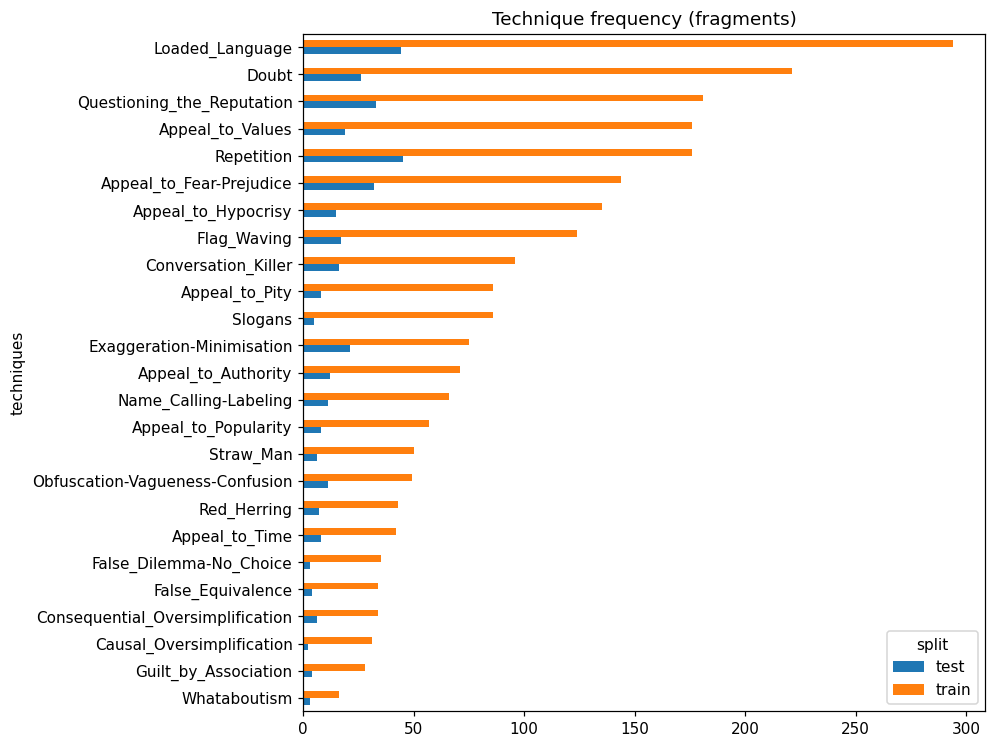

25 techniques. Most / least frequent in train: Loaded_Language 294 / Whataboutism 16
Techniques with < 10 test examples (per-class test F1 will be noisy):
{'Whataboutism': 3, 'Guilt_by_Association': 4, 'Causal_Oversimplification': 2, 'Consequential_Oversimplification': 6, 'False_Equivalence': 4, 'False_Dilemma-No_Choice': 3, 'Appeal_to_Time': 8, 'Red_Herring': 7, 'Straw_Man': 6, 'Appeal_to_Popularity': 8, 'Slogans': 5, 'Appeal_to_Pity': 8}


In [6]:
counts = (df.explode("techniques").dropna(subset=["techniques"])
          .groupby(["techniques", "split"]).size().unstack(fill_value=0)
          .sort_values("train"))
counts.plot.barh(figsize=(8, 8), title="Technique frequency (fragments)")
plt.show()

print(f"{len(counts)} techniques. Most / least frequent in train: {counts['train'].idxmax()} {counts['train'].max()} / {counts['train'].idxmin()} {counts['train'].min()}")
print("Techniques with < 10 test examples (per-class test F1 will be noisy):")
print(counts[counts["test"] < 10]["test"].to_dict())

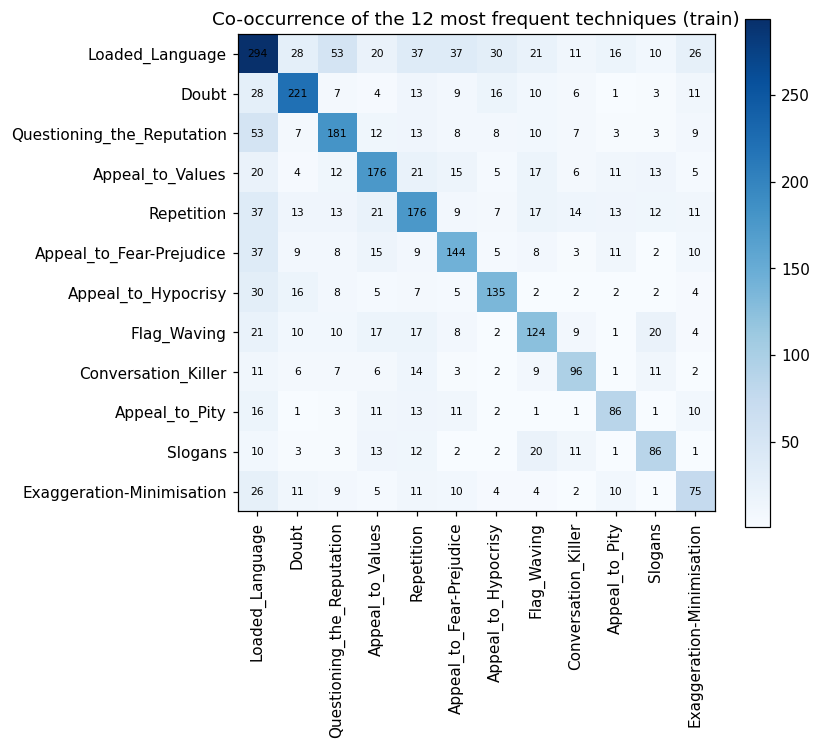

In [7]:
# co-occurrence: how often two techniques label the same fragment
onehot = pd.get_dummies(train["techniques"].explode()).groupby(level=0).max()
top = onehot.sum().nlargest(12).index
co = onehot[top].T.astype(int) @ onehot[top].astype(int)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(co.values, cmap="Blues")
ax.set_xticks(range(len(top)), top, rotation=90); ax.set_yticks(range(len(top)), top)
for i in range(len(top)):
    for j in range(len(top)):
        ax.text(j, i, co.values[i, j], ha="center", va="center", fontsize=7)
ax.set_title("Co-occurrence of the 12 most frequent techniques (train)")
plt.colorbar(im); plt.show()

## 5. Text length

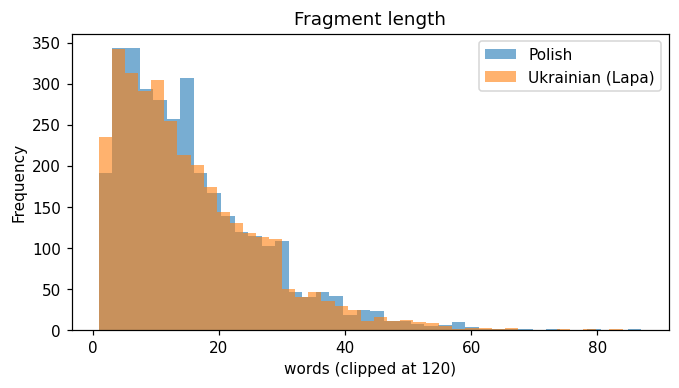

persuasive       False   True 
words_pl count  1551.0  1718.0
         mean     13.0    18.3
         std       9.8    12.0
         min       1.0     1.0
         25%       6.0     9.0
         50%      10.0    16.0
         75%      17.0    25.0
         max      67.0    87.0
words_uk count  1551.0  1718.0
         mean     12.7    17.9
         std       9.7    11.8
         min       1.0     1.0
         25%       5.0     9.0
         50%      10.0    15.0
         75%      17.0    25.0
         max      66.0    84.0

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
df["words_pl"].clip(upper=120).plot.hist(bins=40, alpha=0.6, label="Polish", ax=ax)
df["words_uk"].clip(upper=120).plot.hist(bins=40, alpha=0.6, label="Ukrainian (Lapa)", ax=ax)
ax.set_xlabel("words (clipped at 120)"); ax.legend(); ax.set_title("Fragment length")
plt.show()

display(df.groupby("persuasive")[["words_pl", "words_uk"]].describe().T.round(1))

In [9]:
# token lengths for the model we train (XLM-R): what does max_length truncate?
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("xlm-roberta-base")
df["tokens_uk"] = [len(ids) for ids in tok(df["content_uk"].fillna("").tolist())["input_ids"]]
print(df["tokens_uk"].describe(percentiles=[.5, .9, .99]).round(1).to_dict())
for max_len in (128, 256):
    print(f"max_length={max_len}: {(df['tokens_uk'] > max_len).mean():.2%} of fragments truncated")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

{'count': 3269.0, 'mean': 30.1, 'std': 19.8, 'min': 4.0, '50%': 25.0, '90%': 56.0, '99%': 95.0, 'max': 155.0}
max_length=128: 0.15% of fragments truncated
max_length=256: 0.00% of fragments truncated


## 6. Translation sanity checks (whole dataset)

Automatic checks run over all translated rows: they flag suspicious rows but do not replace the manual and COMET evaluation in `translation_evaluation/`.

,rows flagged
empty,0
too_short (ratio < 0.6),59
too_long (ratio > 1.6),11
polish_letters_left,4
numbers_differ,2


Any flag: 76 of 3269 rows; mean length ratio 0.96


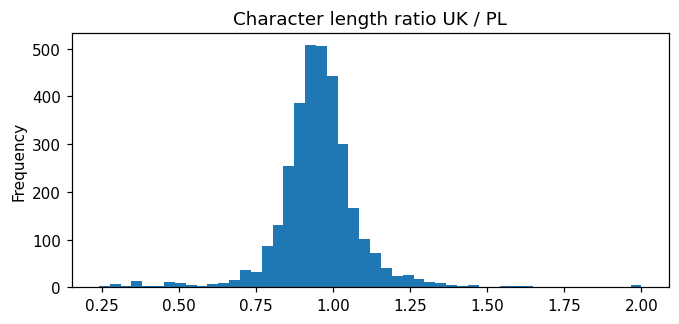

In [10]:
df["len_ratio"] = df["content_uk"].fillna("").str.len() / df["content"].str.len()
nums = lambda s: sorted(re.findall(r"\d+", s))
checks = pd.DataFrame({
    "empty": df["content_uk"].fillna("").str.strip() == "",
    "too_short (ratio < 0.6)": df["len_ratio"] < 0.6,
    "too_long (ratio > 1.6)": df["len_ratio"] > 1.6,
    "polish_letters_left": df["content_uk"].fillna("").str.contains(r"[ąćęłńóśźżĄĆĘŁŃÓŚŹŻ]"),
    "numbers_differ": [nums(a) != nums(str(b)) for a, b in zip(df["content"], df["content_uk"])],
})
display(checks.sum().to_frame("rows flagged"))
print(f"Any flag: {checks.any(axis=1).sum()} of {len(df)} rows; mean length ratio {df['len_ratio'].mean():.2f}")

df["len_ratio"].clip(upper=2).plot.hist(bins=50, figsize=(7, 3), title="Character length ratio UK / PL")
plt.show()

In [11]:
# look at the flagged rows: omissions and additions are the main risk for label preservation
flagged = df[checks.any(axis=1)]
flagged.sample(min(8, len(flagged)), random_state=0)[["content", "content_uk", "techniques", "len_ratio"]]

,content,content_uk,techniques,len_ratio
2214,Poseł Sławomir Ćwik: Szanowny Panie Marszałku!,Шановний пане Маршалку!,[],0.500000
2429,Poseł Alicja Łepkowska-Gołaś: Szanowna Pani Marszałek!,Пані Маршалку!,[],0.259259
1061,Mogę?),Чи можу я?),[],1.833333
3255,Poseł Patryk Wicher: Szanowny Panie Marszałku!,Шановний пане Маршалку!,[],0.500000
1359,"Są, jesteście.",Ви є.,[],0.357143
1323,Poseł Krzysztof Śmiszek: Szanowna Pani Marszałek!,Шановний пане Маршалку!,[],0.469388
3115,To jest 18.,Це 18.,[],0.545455
2246,Poseł Agnieszka Wojciechowska van Heukelom: Szanowni Państwo!,Пані та панове!,[],0.245902


In [12]:
# many "too short" rows are speaker turns ("Poseł X: ...") where Lapa dropped the MP's name
speaker = df[df["content"].str.match(r"Pos\w+ [^:]{3,60}: ")]
dropped = ~speaker["content_uk"].fillna("").str[:80].str.contains(":")
print(f"Speaker-prefixed fragments: {len(speaker)}, name dropped in translation: {dropped.sum()} ({dropped.mean():.0%})")
speaker[dropped][["content", "content_uk"]].head(5)

Speaker-prefixed fragments: 153, name dropped in translation: 43 (28%)


,content,content_uk
34,Poseł Janusz Kowalski: Szanowny Panie Marszałku!,Шановний пане Маршалку!
124,Poseł Bartłomiej Pejo: Panie Marszałku!,Пане Маршалку!
182,Poseł Anna Gembicka: Panie Marszałku!,Пані Маршалку!
189,Poseł Mariusz Krystian: Panie Marszałku!,Пане Маршалку!
209,Poseł Lidia Czechak: Szanowna Pani Marszałek!,Пані Маршалку!


## 7. Examples (one per technique group)

In [13]:
for group in GROUPS:
    row = train[train[group] & (train["n_techniques"] == 1)].sample(1, random_state=1).iloc[0]
    print(f"[{group}] {row['techniques']}")
    print("  PL:", row["content"])
    print("  UK:", row["content_uk"])
    print()

[Attack_on_Reputation] ['Questioning_the_Reputation']
  PL: Są wykorzystywane, traktowane instrumentalnie.
  UK: Їх використовують, ставляться до них як до інструменту.

[Justification] ['Appeal_to_Values']
  PL: Nawet wtedy, kiedy ta decyzja zagraża życiu i zdrowiu pacjentki.
  UK: Навіть тоді, коли це рішення загрожує життю та здоров’ю пацієнтки.

[Distraction] ['Red_Herring']
  PL: To miało miejsce wczoraj czy przedwczoraj w Michałowie, tam byli politycy Platformy Obywatelskiej, nowy marszałek podlaski.
  UK: Це сталося вчора чи позавчора в Міхалові, там були політики Платформи Оборчої, новий маршалок підляський.

[Simplification] ['False_Dilemma-No_Choice']
  PL: Debatujemy dzisiaj o bardzo ważnej i – ośmielę się powiedzieć – kluczowej dla nas sprawie, sprawie życia i śmierci.
  UK: Сьогодні ми обговорюємо дуже важливу і – дозволю собі сказати – ключову для нас справу, справу життя і смерті.

[Call] ['Conversation_Killer']
  PL: Popieranie aborcji przez mężczyzn to dla nich doskona

## 8. Findings

Fill in from the outputs above for the slides. Points to check:
- **Size:** training and test fragment counts, number of documents; small for a 25-label task.
- **Balance:** the binary task is roughly balanced; the 25 techniques are heavily skewed (see section 4) and some have under 10 test examples.
- **Topics:** persuasion rate differs by debate topic.
- **Split:** documents are shared between train and test (fragment-level split).
- **Length:** fragments are mostly single sentences; the truncation share at max_length 128 and 256 decides the model setting.
- **Translation:** how many rows the automatic checks flag, and what the flagged examples show.